In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import jax
from jax.typing import ArrayLike
from jax import numpy as jnp # JAX version of NumPy.
from flax import nnx # Neural networks in JAX.
import optax # Optimization in JAX.
import gymnasium as gym
import numpy as np # For compatibility with gymnasium.
from tqdm import tqdm
import pennylane as qml
import json
import yaml
import tyro
from pathlib import Path
import qnrl
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True) # Enable double-precision (default is single-precision).

In [3]:
import wandb

wandb.login()

wandb: Currently logged in as: zanderman (zanderman-virginia-tech) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [4]:
# Create default configuration storage object.
store = qnrl.store.HashStore()

In [5]:
def inspect_model_pmfs_for_observation(obs, model, atoms):
    """Display the model return-atom density matrix for a given observation."""
    
    # Put single observation into a 1-batch for input to model.
    observations = jnp.array([obs])

    # Generate action PMF for current observation.
    return_pmfs = model(observations)
    return_pmfs = return_pmfs[0] # There's only 1 item in batch.
    
    
    ## Display the observation.
    print(f"{observations = }")
    
    # Compute Q-value for each action.
    Q = jnp.array([jnp.sum(rpmf * atoms) for a, rpmf in enumerate(return_pmfs)])
    
    for a, q in enumerate(Q):
        print(f"Q(a{a}): {q}")
    
    best_action = jnp.argmax(Q)
    print(f"{best_action.item() = }")
    
    figures = []
    
    
    
    ### Show a matplotlib figure for PDF render.
    #
    ## Action PMF.
    # fig = plt.figure()
    # ax = fig.add_subplot(111)
    # x = jnp.arange(action_pmf[0].shape[-1])
    # ax.bar(x, action_pmf[0])
    # ax.set_xticks(x, [f"$a_{{{i}}}$" for i in range(len(x))], rotation=90)
    # ax.set_xlabel("Action atom")
    # ax.set_ylabel("Probability")
    # ax.set_title("Action PMF based on return-atom amplitude kickback")
    #
    ## Plot the return PMF for each action individually.
    n_actions, n_returns = return_pmfs.shape
    fig = plt.figure()
    x = jnp.arange(n_returns)
    fig, axs = plt.subplots(n_actions, 1, sharex=True, sharey=True)
    figures.append(fig)
    axs = axs.flatten()
    for a in range(n_actions):
        axs[a].bar(jnp.arange(n_returns), return_pmfs[a])
        axs[a].set_xticks(x, [f"$z_{{{i}}}$" for i in range(len(x))], rotation=90)
        axs[a].set_title(f"$a_{{{a}}}$")
        axs[a].set_xlabel("Return atom")
        axs[a].set_ylabel("Probability")
    fig.suptitle("Return-atom PMF for each action $a_i$")
    plt.tight_layout()
    
    return figures

def inspect_model_pmfs_for_env(env, model, atoms):
    """Display the model return-atom density matrix for a random environment observation."""
    
    # Generate a batch of environment observations.
    # observations = jnp.array([env.reset()[0] for _ in range(config.batch_size)])
    # 
    obs = env.reset()[0]
    # for _ in range(10): obs = env.step(0)[0] # Mutate the environment to get a different observation.
    # observations = jnp.array([obs for _ in range(config.batch_size)])
    figures = inspect_model_pmfs_for_observation(obs, model, atoms)
    
    return obs, figures

In [6]:
from qnrl.algorithms.c51 import C51
from qnrl.optimizer import *
from qnrl.environment import *
from qnrl.modules import Sequential, DistQNetworkLinear

import ale_py
gym.register_envs(ale_py)

# # CartPole.
# env_id = "CartPole-v1"
# env = EnvConfig(env_id=env_id)
# din = 4
# num_actions = 2
# z_min = -100
# z_max = 100
# total_timesteps = 100_000
# ##
# # z_min = 0
# # z_max = 500
# ##
# # douts = [16,8]
# douts = [30,21]
# # douts = [60,42]
# ###

# FrozenLake-v1
env_id = "FrozenLake-v1"
# din = 1
din = 16
num_actions = 4
# env = EnvConfig(env_id=env_id)
# env = ObservationExpandDims(env=EnvConfig(env_id=env_id), axis=0)
# env = ObservationExpandDims(env=EnvConfig(env_id=env_id, extra_args=dict(reward_schedule=(2,-1,-0.01))), axis=0)
# env = ObservationDiscreteOneHot(env=EnvConfig(env_id=env_id, extra_args=dict(reward_schedule=(2,-1,-0.01))))
env = ObservationDiscreteOneHot(env=EnvConfig(env_id=env_id, extra_args=dict(reward_schedule=(1.0,-0.2,-0.01), map_name="4x4"), max_episode_steps=100)) # See reward schedule from https://ieeexplore.ieee.org/document/9144562
# z_min = -100
# z_max = 100
###
# z_min = -2
# z_max = 1
###
z_min = -2
z_max = 2
###
total_timesteps = 100_000
# douts = [30,21]
douts = [15,10]
# douts = [7,5]

# # CliffWalking-v1
# # din = 1
# # din = 2
# din = 48
# num_actions = 4
# env_id = "CliffWalking-v1"
# # env = EnvConfig(env_id="CliffWalking-v1")
# # env = ObservationExpandDims(env=EnvConfig(env_id=env_id, max_episode_steps=99), axis=0)
# env = ObservationDiscreteOneHot(env=EnvConfig(env_id=env_id, max_episode_steps=99))
# # env = ObservationDiscreteUnravel(env=EnvConfig(env_id=env_id, max_episode_steps=99), shape=(4,12))
# z_min = -100
# z_max = 100
# total_timesteps = 100_000
# douts = [30,21]

# # MountainCar.
# env_id = "MountainCar-v0"
# env = EnvConfig(env_id=env_id)
# din = 2
# num_actions = 3
# z_min = -100
# z_max = 100
# ###
# # z_min = -200
# # z_max = -1
# ###
# total_timesteps = 100_000
# douts = [30,21]

# # Acrobot-v1
# din = 6
# num_actions = 3
# env = EnvConfig(env_id="Acrobot-v1")
# z_min = -100
# z_max = 100
# total_timesteps = 100_000
# ###
# # z_min = -500
# # z_max = -1
# ###
# douts = [30,21]
# # douts = [60,42]



# # ALE/Asteroids-v5
# din = 128
# num_actions = 14
# env = EnvConfig(env_id="ALE/Asteroids-v5", extra_args=dict(obs_type="ram"))
# z_min = 1
# z_max = 10000

# num_atoms = 101
# num_atoms = 2**7
num_atoms = 2**5

batch_size = 128

seed = 0
# seed = 21
# seed = 42
# seed = 73
# seed = 96

# Experiment configuration.
config = C51(
    buffer_size=10_000,
    seed=seed,
    batch_size=batch_size,
    # total_timesteps=500_000,
    # total_timesteps=100_000,
    # total_timesteps=50_000,
    # total_timesteps=20_000, # quick test default.
    total_timesteps=total_timesteps,
    learning_starts=10_000,
    policy_update_frequency=10,
    target_update_frequency=500,
    gamma=0.99, # default
    # gamma=0.95,
    tau=1.0,
    eps_start=1,
    eps_end=5e-2,
    eps_exploration=0.5, # default
    # eps_exploration=0.75,
    #
    # env=EnvConfig(env_id="CartPole-v1"),
    # env=EnvConfig(env_id="MountainCar-v0"),
    env=env,
    num_atoms=num_atoms,
    z_min=z_min,
    z_max=z_max,
    model=Sequential(
        layers={
            # 'RescaleInput': RescaleInput(scale=[2.4, 2.5, 0.21, 2.5]),
            'QNetworkLinear': DistQNetworkLinear(
                din=din,
                num_actions=num_actions,
                num_atoms=num_atoms,
                # douts=[120, 84],
                # douts=[120,],
                # douts=[60,42], # Does well at 20,000 epochs.
                # douts=[30,21], # Does not solve at 20,000 epochs.
                # douts=[15,10],
                # douts=[16,8],
                # douts=[30,],
                # douts=[60,],
                douts=douts,
                rngs_kwargs=dict(default=seed),
            ),
        },
    ),
    # optimizer=Adam(learning_rate=2.5e-4),
    # optimizer=Adam(learning_rate=2.5e-3),
    # optimizer=Adam(learning_rate=1e-3, eps=0.01/batch_size),
    optimizer=Adam(learning_rate=1e-3),
)

if store.exists(config):
    print(f"Already exists in store")
    cfg_hash, cfg_str = store.hash(config)
else:
    print(f"New hash")
    # Generate hash for the current config and store it for later retrieval.
    cfg_hash, cfg_str = store.store_obj(config)

print(f"Config String: {cfg_str}")
print(f"Config Hash: {cfg_hash}")

Already exists in store
Config String: {"type": "C51", "env": {"type": "ObservationDiscreteOneHot", "env": {"type": "EnvConfig", "env_id": "FrozenLake-v1", "render_mode": null, "max_episode_steps": 100, "extra_args": {"reward_schedule": [1.0, -0.2, -0.01], "map_name": "4x4"}}, "num_classes": null}, "seed": 0, "metric_manager": null, "checkpoint": null, "model": {"type": "Sequential", "layers": {"QNetworkLinear": {"type": "DistQNetworkLinear", "din": 16, "num_actions": 4, "num_atoms": 32, "douts": [15, 10], "rngs_kwargs": {"default": 0}}}, "key_order": ["QNetworkLinear"]}, "optimizer": {"type": "Adam", "learning_rate": 0.001, "b1": 0.9, "b2": 0.999, "eps": 1e-08, "eps_root": 0.0, "mu_dtype": null, "nesterov": false}, "num_atoms": 32, "z_min": -2.0, "z_max": 2.0, "buffer_size": 10000, "batch_size": 128, "total_timesteps": 100000, "learning_starts": 10000, "policy_update_frequency": 10, "target_update_frequency": 500, "gamma": 0.99, "tau": 1.0, "eps_start": 1.0, "eps_end": 0.05, "eps_expl

In [7]:
qnrl.tools.get_model_total_parameter_count(config.model)

1823

In [8]:
for i,l in enumerate(config.model.layers['QNetworkLinear'].layers):
    print(f"[{i}] {l.in_features = }, {l.out_features}")

[0] l.in_features = 16, 15
[1] l.in_features = 15, 10
[2] l.in_features = 10, 128


In [9]:
# Print all the parameters.
nnx.state(config.model, nnx.Param)

State({
  'layers': {
    'QNetworkLinear': {
      'layers': {
        0: {
          'bias': Param( # 15 (60 B)
            value=Array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],      dtype=float32)
          ),
          'kernel': Param( # 240 (960 B)
            value=Array([[ 0.26754445, -0.24243177, -0.2011131 , -0.30962813, -0.23332502,
                     0.15886953,  0.19472086, -0.27304402,  0.42189467, -0.465495  ,
                    -0.33829   ,  0.03623525, -0.30508685,  0.06486067,  0.438537  ],
                   [ 0.13646084,  0.16052653, -0.12783015,  0.2448376 ,  0.09779356,
                    -0.17093852, -0.23313214,  0.20380248,  0.28248975,  0.24295433,
                    -0.13305682,  0.2378073 ,  0.41854542, -0.5413056 ,  0.11948797],
                   [ 0.4522912 , -0.31006622, -0.15883712,  0.50456154,  0.21522272,
                    -0.05353428, -0.4375615 , -0.22033681, -0.5287693 ,  0.39883754,
                     0.36576006,  0.09

In [10]:
jnp.asarray(np.linspace(start=z_min, stop=z_max, num=num_atoms))

Array([-2.        , -1.87096774, -1.74193548, -1.61290323, -1.48387097,
       -1.35483871, -1.22580645, -1.09677419, -0.96774194, -0.83870968,
       -0.70967742, -0.58064516, -0.4516129 , -0.32258065, -0.19354839,
       -0.06451613,  0.06451613,  0.19354839,  0.32258065,  0.4516129 ,
        0.58064516,  0.70967742,  0.83870968,  0.96774194,  1.09677419,
        1.22580645,  1.35483871,  1.48387097,  1.61290323,  1.74193548,
        1.87096774,  2.        ], dtype=float64)

observations = Array([[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], dtype=int8)
Q(a0): 0.034971888868077984
Q(a1): 0.05656959765380426
Q(a2): 0.02832127194250795
Q(a3): -0.025981843711868416
best_action.item() = 1


<Figure size 640x480 with 0 Axes>

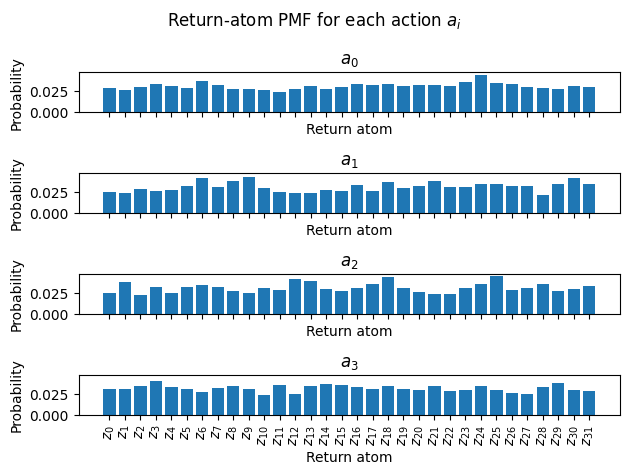

In [11]:
# Inspect density matrices before training.
# Preserve the observation that was used to compare inspect after training.
atoms = jnp.linspace(start=config.z_min, stop=config.z_max, num=config.num_atoms)
obs_inspect, _ = inspect_model_pmfs_for_env(config.env.make(), config.model, atoms)

In [12]:
from qnrl.metric import LocalFileMetricManager, WandBMetricManager


do_train = True
save_metrics = True
###
metric_filepath = Path(f"./metrics/{cfg_hash}")
# metric_manager = LocalFileMetricManager(
#     metric_dir=metric_filepath.resolve(),
#     metric_file_type="json",
#     save_interval_steps=1,
#     max_to_keep=1,
#     )
###
metric_manager = WandBMetricManager(
    login=False, # Already logged in at beginning of notebook.
    project="qnrl",
    name=f"c51/{env_id}/{cfg_hash}",
    config=config.to_dict(),
    monitor_gym=False,
    save_code=True, # Preserve notebook.
    terminate_on_wait_until_finished=False,
    define_metrics=[
        {"name": "*", "summary": "min"},
        {"name": "*", "summary": "max"},
        {"name": "*", "summary": "mean"},
        {"name": "*", "summary": "first"},
        {"name": "*", "summary": "last"},
    ],
)

In [13]:
# if metric_filepath.exists() and not train:
if not do_train:
    print(f"Loading existing train results")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    history_list = qnrl.tools.load_train_results(metric_filepath)
    history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
else:
    print(f"Training")
    print(f"Store: {store.path}")
    print(f"Hash: {cfg_hash}")
    print(f"History: {metric_filepath}")
    
    history_list = config.train(
        metric_manager=metric_manager if save_metrics else None,
    )
    history_dict = qnrl.tools.listofdict_to_dictoflist(history_list)
    
    # Preserve training results.
    if save_metrics:
        qnrl.tools.save_train_results(metric_filepath, history_list)

Training
Store: hashstore.json
Hash: 0f40d5b4-fd76-5047-b610-b8fec428a964
History: metrics/0f40d5b4-fd76-5047-b610-b8fec428a964


 10%|▉         | 9938/100000 [00:09<01:35, 946.57step/s, train/episode_step=1e+4, train/episode_reward=-0.22, train/episode_length=3, train/episode_time=0.00271, train/episode_utcisotime=2025-12-09T20:19:31.316201+00:00]  /Users/derieux/research/qnrl/.venv/lib/python3.12/site-packages/jax/_src/ops/scatter.py:108: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=float64 to dtype=float32 with jax_numpy_dtype_promotion='standard'. In future JAX releases this will result in an error.
  warnings.warn(
100%|██████████| 100000/100000 [02:14<00:00, 742.64step/s, train/episode_step=99947, train/episode_reward=-0.26, train/episode_length=7, train/episode_time=0.0108, train/episode_utcisotime=2025-12-09T20:21:36.147484+00:00, train/loss_step=1e+5, train/loss=2.558587, train/metric_step=1e+5, train/cross_entropy=2.560629, train/kl_div=0.038153976]      


Text(0, 0.5, 'episode_reward')

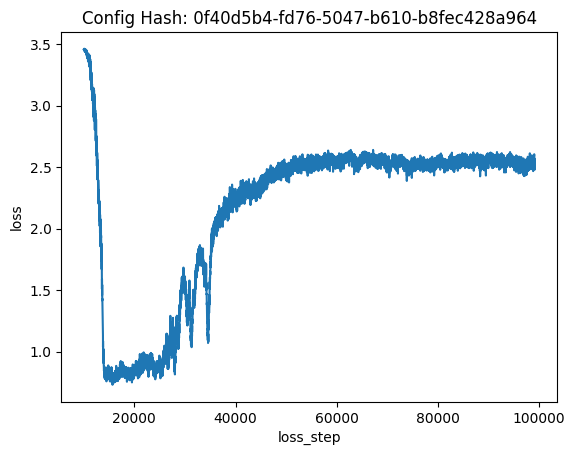

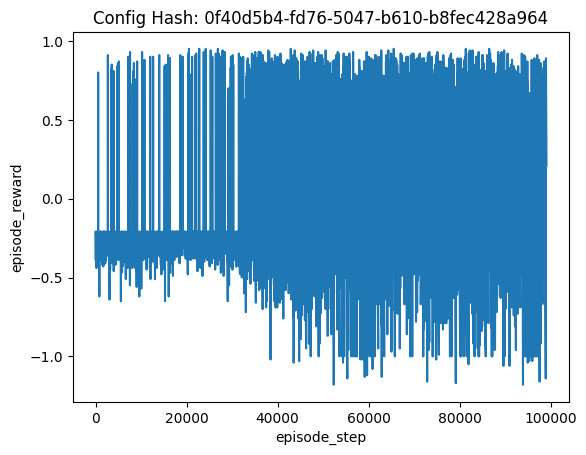

In [14]:
import matplotlib.pyplot as plt

# history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))
metric_manager.load()
history_dict = metric_manager.get_dataframe()

plt.figure()
plt.title(f"Config Hash: {cfg_hash}")
plt.plot(history_dict['train/loss_step'].dropna(), history_dict['train/loss'].dropna())
plt.xlabel('loss_step')
plt.ylabel('loss')

plt.figure()
plt.title(f"Config Hash: {cfg_hash}")
plt.plot(history_dict['train/episode_step'].dropna(), history_dict['train/episode_reward'].dropna())
plt.xlabel('episode_step')
plt.ylabel('episode_reward')

In [15]:
# # Plot loss and episode reward on the same plot.

# history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))

# fig, axs = plt.subplots(2,1, sharex=True, figsize=(10,8))
# axs = axs.squeeze()

# axs[0].set_title(f"Config Hash: {cfg_hash}")
# plt.xlabel('step')

# # Only consider data points that are after learning starts (because this is where loss starts accumulating).
# idx = np.array(history_dict['loss_step']) >= config.learning_starts
# history_dict['loss_step'] = np.array(history_dict['loss_step'])[idx]
# history_dict['loss'] = np.array(history_dict['loss'])[idx]

# # Only consider data points that are after learning starts (because this is where loss starts accumulating).
# idx = np.array(history_dict['episode_step']) >= config.learning_starts
# history_dict['episode_step'] = np.array(history_dict['episode_step'])[idx]
# history_dict['episode_reward'] = np.array(history_dict['episode_reward'])[idx]

# axs[0].plot(history_dict['loss_step'], history_dict['loss'])
# axs[0].set_ylabel('loss')
# axs[0].grid() # Turn on a grid.

# axs[1].plot(history_dict['episode_step'], history_dict['episode_reward'])
# axs[1].set_ylabel('episode_reward')
# axs[1].grid() # Turn on a grid.

# # Save the figure file.
# figfile = f"./figures/{cfg_hash}.pdf"
# fig.savefig(figfile)
# print(figfile)

In [16]:
# ###
# # Inspect the metrics.
# ###
# idxmax = history_dict['episode_reward'] == max(history_dict['episode_reward'])
# idxmin = history_dict['episode_reward'] == min(history_dict['episode_reward'])

# firstmax = sorted(list(zip(history_dict['episode_step'][idxmax], history_dict['episode_reward'][idxmax])), key=lambda tup: tup[0])[0]
# firstmin = sorted(list(zip(history_dict['episode_step'][idxmin], history_dict['episode_reward'][idxmin])), key=lambda tup: tup[0])[0]

# print(f"{firstmax = }")
# print(f"{firstmin = }")

In [17]:
eval_metric_list = config.eval()
eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)

for key in ('eval/episode_step','eval/episode_reward','eval/episode_length','eval/episode_time',):
    print(f"{key}: {eval_metric_dict[key][0]}")

  0%|          | 53/100000 [00:00<00:39, 2503.41step/s, eval/episode_step=53, eval/episode_reward=-0.73, eval/episode_length=54, eval/episode_time=0.0217]

eval/episode_step: 53
eval/episode_reward: -0.7300000000000002
eval/episode_length: 54
eval/episode_time: 0.021686


observations = Array([[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]], dtype=int8)
Q(a0): 0.20707386806803774
Q(a1): 0.20098253731078228
Q(a2): 0.19414806546181698
Q(a3): 0.1871538014484177
best_action.item() = 0


<Figure size 640x480 with 0 Axes>

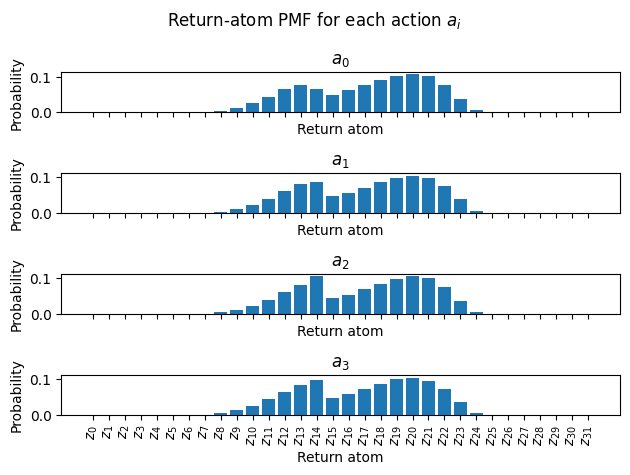

In [18]:
# Inspect the model again using the same observation used prior to training.
figures = inspect_model_pmfs_for_observation(obs_inspect, config.model, atoms)

metric_manager.run.log({"inspect_model_pmfs_for_observation": [wandb.Image(f) for f in figures], "observation": obs_inspect})

In [19]:
# obs_tmp=jnp.array([ 0.01716913, -0.02654778, -0.04510068, -0.00686742])
# inspect_model_pmfs_for_observation(obs_tmp, config.model, atoms)

In [20]:
# inspect_model_pmfs_for_observation(jnp.array([-0.01053775,  0.03950866, -0.03218421, -0.04678081]), config.model, atoms)

In [21]:
eval_metric_list = config.eval()
eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)

for key in ('eval/episode_step','eval/episode_reward','eval/episode_length','eval/episode_time',):
    print(f"{key}: {eval_metric_dict[key][0]}")

  0%|          | 53/100000 [00:00<00:34, 2916.57step/s, eval/episode_step=53, eval/episode_reward=-0.73, eval/episode_length=54, eval/episode_time=0.0186]

eval/episode_step: 53
eval/episode_reward: -0.7300000000000002
eval/episode_length: 54
eval/episode_time: 0.01857


In [22]:
# Evaluate multiple times and preserve results.
# n_runs = 10
# n_runs = 50
n_runs = 100
# n_runs = 1000
eval_metric_dict_runs = []
key = jax.random.PRNGKey(seed=config.seed)
for r in range(n_runs):
    
    # Generate a new random key.
    key, subkey = jax.random.split(key=key)
    
    seed_eval = int(subkey[0])
    eval_metric_list = config.eval(seed=seed_eval)
    eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)
    eval_metric_dict['eval/seed'] = [seed_eval]
    eval_metric_dict_runs.append(eval_metric_dict)
    
    d = {k: v[0] for k, v in eval_metric_dict.items() if 'eval/' in k}
    metric_manager.run.log(d)

# Report statistics across all runs.
for key in ('eval/episode_step','eval/episode_reward','eval/episode_length','eval/episode_time',):
    l = jnp.array([d[key][0] for d in eval_metric_dict_runs]) # Each key only has 1 entry.
    print(f"{key}: min: {jnp.min(l)}")
    print(f"{key}: max: {jnp.max(l)}")
    print(f"{key}: mean: {jnp.mean(l)}")
    print(f"{key}: std: {jnp.std(l)}")

  0%|          | 9/100000 [00:00<00:37, 2665.87step/s, eval/episode_step=9, eval/episode_reward=0.91, eval/episode_length=10, eval/episode_time=0.00352]


eval/episode_step: min: 7
eval/episode_step: max: 99
eval/episode_step: mean: 40.45
eval/episode_step: std: 27.595425345516965
eval/episode_reward: min: -1.1200000000000006
eval/episode_reward: max: 0.9299999999999999
eval/episode_reward: mean: 0.22859999999999978
eval/episode_reward: std: 0.6663512887359041
eval/episode_length: min: 8
eval/episode_length: max: 100
eval/episode_length: mean: 41.45
eval/episode_length: std: 27.595425345516965
eval/episode_time: min: 0.002334
eval/episode_time: max: 0.021984
eval/episode_time: mean: 0.008777769999999999
eval/episode_time: std: 0.005336395404868347


## Record a run as a video

tmpdir = '/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/tmp8_ovt2v9'


/Users/derieux/research/qnrl/.venv/lib/python3.12/site-packages/gymnasium/wrappers/rendering.py:293: UserWarning: WARN: Overwriting existing videos at /var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/tmp8_ovt2v9 folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(
/Users/derieux/research/qnrl/.venv/lib/python3.12/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
  0%|          | 25/100000 [00:00<00:54, 1841.35step/s, eval/episode_step=25, eval/episode_reward=0.75, eval/episode_length=26, eval/episode_time=0.269]


eval/episode_step: min: 25
eval/episode_step: max: 25
eval/episode_step: mean: 25.0
eval/episode_step: std: 0.0
eval/episode_reward: min: 0.75
eval/episode_reward: max: 0.75
eval/episode_reward: mean: 0.75
eval/episode_reward: std: 0.0
eval/episode_length: min: 26
eval/episode_length: max: 26
eval/episode_length: mean: 26.0
eval/episode_length: std: 0.0
eval/episode_time: min: 0.269151
eval/episode_time: max: 0.269151
eval/episode_time: mean: 0.269151
eval/episode_time: std: 0.0
os.listdir(tmpdir) = ['rl-video-episode-0.mp4']
MoviePy - Building file /var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/tmp8_ovt2v9/rl-video-episode-0.gif with imageio.


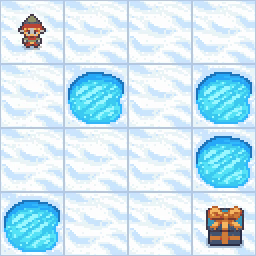

In [23]:
import os
import tempfile
from IPython.display import display, Video, Image
from moviepy import VideoFileClip

with tempfile.TemporaryDirectory() as tmpdir:
    print(f"{tmpdir = }")

    # Create wrapper for recording video.
    env_wrappers = [
        lambda env: gym.wrappers.RecordVideo(env, video_folder=tmpdir, episode_trigger=lambda x: True, disable_logger=True),
    ]
    
    # Evaluate multiple times and preserve results.
    n_runs = 1
    eval_metric_dict_runs = []
    key = jax.random.PRNGKey(seed=1423)
    for r in range(n_runs):
        
        # Generate a new random key.
        key, subkey = jax.random.split(key=key)
        
        # Evaluate the model within environment seeded from random subkey.
        eval_metric_list = config.eval(seed=int(subkey[0]), env=config.env.make(render_mode='rgb_array'), model_policy=config.model, total_timesteps=config.total_timesteps, env_wrappers=env_wrappers)
        eval_metric_dict = qnrl.tools.listofdict_to_dictoflist(eval_metric_list)
        eval_metric_dict['seed'] = int(subkey[0])
        eval_metric_dict_runs.append(eval_metric_dict)

    # Report statistics across all runs.
    for key in ('eval/episode_step','eval/episode_reward','eval/episode_length','eval/episode_time',):
        l = jnp.array([d[key][0] for d in eval_metric_dict_runs]) # Each key only has 1 entry.
        print(f"{key}: min: {jnp.min(l)}")
        print(f"{key}: max: {jnp.max(l)}")
        print(f"{key}: mean: {jnp.mean(l)}")
        print(f"{key}: std: {jnp.std(l)}")
    
    print(f"{os.listdir(tmpdir) = }")
    
    videofilepath = Path(tmpdir)/os.listdir(tmpdir)[0]
    
    # Build a GIF from the video file.
    giffilepath = Path(tmpdir)/(videofilepath.stem + '.gif')
    clip = VideoFileClip(videofilepath)
    clip.write_gif(giffilepath, fps=15)
    
    # display(Video(videofilepath, embed=True, html_attributes="controls muted loop autoplay"))
    display(Image(filename=giffilepath))

In [24]:
metric_manager.run.finish()

eval/episode_length,▂▂▁▃▂▄▃██▃▁▁▄▂█▇▃▂▆▃▄▆▄▁▂▅▆▅▄▃▂▃▆▄▂▄▃▃▁█
eval/episode_reward,▃█▇█▇██▇▅▇▁█▃▇▇▆▇█▁▇▆▆▆▇▆▂▇▆█▇▃██▆▂▇█▁▇█
eval/episode_step,▂▁▂▂▁▂▂▄▁▂▁█▆▃█▇▃▅▁▆▁▄▄▃▆▄▃▃▅▆▁▃▂▁▁█▄█▃▅
eval/episode_time,▃▂▁▂▁▁▂▂▄▂▂█▂█▁██▂▂▃▄▂▂▆▃▄▆▇▆▄▃▂▄▃▂▇▃▇▇▁
eval/seed,▃▇█▂▃█▆▃▁▄▁▆▂▁▄▇█▁▁█▄▇▂▃█▇▃▆▄▁█▅█▄█▃▇█▆▁
train/cross_entropy,█▇▆▄▄▁▁▁▂▂▃▃▂▄▃▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▆▆▆▆▆▆▆▆▆
train/episode_length,▁▁▂▂▁▁▁▂▁▂▁▁▂▁▁▂▁▂▁▁▂▁▂▁▁▂▂▁▂▃▅▂▃▂▃▂▂▄█▅
train/episode_reward,▃▃▃▂▃▃█▃▃▃▃▃▃▃▃▃▃▃▃▃▂▃▃▂▃▃█▃█▇▃▂▇▂▃▂▂▇▁▅
train/episode_step,▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▅▅▆▆▆▆██
train/episode_time,▁▂▁▁▁▁▁▁▂▁▁▁▂▁▁▁▁▂▁▁▁▂▁▂▂▂▃▄▂▃▂▃█▅▄▃▂▃▁▂
+4,...


In [25]:
# Print all the parameters.
nnx.state(config.model, nnx.Param)

State({
  'layers': {
    'QNetworkLinear': {
      'layers': {
        0: {
          'bias': Param( # 15 (60 B)
            value=Array([0.24433984, 0.16275232, 0.26888606, 0.04548001, 0.27149493,
                   0.1121259 , 0.22730099, 0.3391913 , 0.05184726, 0.15217562,
                   0.22980337, 0.2293123 , 0.27079022, 0.31364632, 0.0115162 ],      dtype=float32)
          ),
          'kernel': Param( # 240 (960 B)
            value=Array([[ 0.49322873, -0.25426954, -0.30231115, -0.30962813, -0.3148698 ,
                     0.01259607,  0.17919655, -0.24945806,  0.70456946, -0.465495  ,
                    -0.33829   ,  0.1848569 , -0.30508685, -0.02140229,  0.6482499 ],
                   [ 0.09756803, -0.00413832, -0.07433979,  0.2352581 ,  0.21963446,
                    -0.19130738, -0.10729402,  0.3428554 ,  0.40949497,  0.5431145 ,
                    -0.26533768,  0.39049816,  0.42407906, -0.5413056 ,  0.2863468 ],
                   [ 0.17557426, -0.31006622, -0.1